# FOVL Assignment — Multilingual Word Embeddings for Indian Languages
**Name:** Aishwarya Mishra  **USN / Roll No.:** G25AIT2137

FastText (skip-gram with character n-grams), **300-d**, trained **from scratch on IndicCorpV2 only**
(`rony000013/indiccorpV2-5k`), evaluated on the Akhtar et al. (2017) word-similarity benchmark
(Gujarati, Hindi, Marathi, Punjabi, Tamil, Telugu, Urdu).

OOV handling: every word (in-vocabulary or not) is represented through its character n-grams
(FastText subword hashing), so no word pair is ever dropped. Multi-word entries (e.g. Urdu `کی بورڈ`)
are embedded as the mean of their token vectors.

**Corpus facts:** `data.parquet` (118,243 documents, 24 languages, columns `language`, `code`, `text`). The model is trained on the 7 benchmark languages (35,000 documents, 1.69M tokens); §7 shows that adding the other 17 languages did not help.

**Run modes:** `TRAIN_FINAL=False` loads the saved model from `model/` (fast, reproduces the reported numbers exactly); `True` retrains from scratch (≈15 min on 2 CPU cores). `RUN_EXPERIMENTS=True` re-runs every experiment in §7 (≈1 h).

**Section map:** 1 Setup · 2 Data · 3 Preprocessing · 4 Benchmark · 5 Embedding + OOV · 6 Evaluation ·
7 Experiments · 8 Final model · 9 Coverage/OOV · 10 Export (.npy + vocab) · 11 t-SNE · 12 Analysis ·
13 **Inference API for private evaluation** (load model → embeddings for any word, incl. OOV).

## 1. Setup

In [1]:
# !pip install -q gensim==4.4.0 huggingface_hub datasets regex scipy scikit-learn matplotlib indic_transliteration pyarrow
import os, re, json, glob, random, unicodedata, time, subprocess
from collections import Counter, defaultdict
import numpy as np, pandas as pd, regex
from scipy.stats import spearmanr
from gensim.models import FastText

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DIM = 300                                   # required embedding dimension
WORKERS = max(1, os.cpu_count() or 1)
BASE = os.path.abspath('.')
DATA_DIR   = os.path.join(BASE, 'data')
CORPUS_DIR = os.environ.get('CORPUS_DIR', os.path.join(DATA_DIR, 'indiccorpV2-5k'))   # local copy of the HF dataset
BENCH_DIR  = os.path.join(DATA_DIR, 'ws')
OUT_DIR    = os.path.join(BASE, 'outputs')
MODEL_DIR  = os.path.join(BASE, 'model')
for d in (DATA_DIR, OUT_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
HF_REPO = 'rony000013/indiccorpV2-5k'
BENCH_LANGS = ['Gujarati', 'Hindi', 'Marathi', 'Punjabi', 'Tamil', 'Telugu', 'Urdu']
TRAIN_FINAL = False        # True = retrain the final model from scratch
RUN_EXPERIMENTS = False    # True = re-run all experiments of section 7

## 2. Training data — IndicCorpV2 (5k subset)
Downloads the dataset repo once (or uses `CORPUS_DIR` if already present) and reads every text file regardless of format.

In [2]:
def download_corpus():
    if os.path.isdir(CORPUS_DIR) and any(os.scandir(CORPUS_DIR)):
        print('Using local corpus at', CORPUS_DIR); return
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id=HF_REPO, repo_type='dataset', local_dir=CORPUS_DIR)
    print('Downloaded', HF_REPO, '->', CORPUS_DIR)
download_corpus()

# language identification from file path (ISO codes / names / FLORES-style codes)
LANG_ALIASES = {
 'Hindi':['hi','hin','hindi','hin_deva'], 'Marathi':['mr','mar','marathi','mar_deva'],
 'Gujarati':['gu','guj','gujarati','guj_gujr'], 'Punjabi':['pa','pan','pnb','punjabi','pan_guru'],
 'Tamil':['ta','tam','tamil','tam_taml'], 'Telugu':['te','tel','telugu','tel_telu'],
 'Urdu':['ur','urd','urdu','urd_arab'], 'Bengali':['bn','ben','bengali','ben_beng'],
 'Kannada':['kn','kan','kannada','kan_knda'], 'Malayalam':['ml','mal','malayalam','mal_mlym'],
 'Odia':['or','ori','ory','odia','oriya'], 'Assamese':['as','asm','assamese'], 'Nepali':['ne','nep','npi','nepali'],
 'Sanskrit':['sa','san','sanskrit'], 'Sindhi':['sd','snd','sindhi'], 'Kashmiri':['ks','kas','kashmiri'],
 'Maithili':['mai','maithili'], 'Konkani':['gom','kok','konkani'], 'Bodo':['brx','bodo'], 'Dogri':['doi','dogri'],
 'Manipuri':['mni','manipuri'], 'Santali':['sat','santali'], 'Khasi':['kha','khasi'], 'English':['en','eng','english'],
}
ALIAS2LANG = {a: L for L, al in LANG_ALIASES.items() for a in al}
def lang_from_path(p):
    toks = [t.lower() for t in re.split(r'[\\/_.\-=]+', os.path.relpath(p, CORPUS_DIR))]
    for i in range(len(toks)-1):                       # e.g. hin_Deva
        if f'{toks[i]}_{toks[i+1]}' in ALIAS2LANG: return ALIAS2LANG[f'{toks[i]}_{toks[i+1]}']
    for t in reversed(toks):
        if t in ALIAS2LANG: return ALIAS2LANG[t]
    return None

SCRIPT_RANGES = [('Devanagari',0x0900,0x097F),('Bengali',0x0980,0x09FF),('Gurmukhi',0x0A00,0x0A7F),
                 ('Gujarati',0x0A80,0x0AFF),('Odia',0x0B00,0x0B7F),('Tamil',0x0B80,0x0BFF),('Telugu',0x0C00,0x0C7F),
                 ('Kannada',0x0C80,0x0CFF),('Malayalam',0x0D00,0x0D7F),('Arabic',0x0600,0x06FF),('Latin',0x41,0x7A)]
def dominant_script(s):
    c = Counter()
    for ch in s[:400]:
        o = ord(ch)
        for name, a, b in SCRIPT_RANGES:
            if a <= o <= b: c[name] += 1; break
    return c.most_common(1)[0][0] if c else None
SCRIPT2LANG = {'Gurmukhi':'Punjabi','Gujarati':'Gujarati','Tamil':'Tamil','Telugu':'Telugu','Arabic':'Urdu',
               'Bengali':'Bengali','Odia':'Odia','Kannada':'Kannada','Malayalam':'Malayalam','Latin':'English',
               'Devanagari':'Devanagari(unk)'}

TEXT_COLS = ['text','sentence','sentences','content','line','document','data']
def iter_file(path):
    ext = path.lower().rsplit('.', 1)[-1]
    if ext in ('txt','text'):
        with open(path, encoding='utf-8', errors='ignore') as f:
            for line in f: yield line.rstrip('\n'), None
        return
    if ext == 'parquet': df = pd.read_parquet(path)
    elif ext in ('jsonl','json'):
        try: df = pd.read_json(path, lines=True)
        except ValueError: df = pd.read_json(path)
    elif ext in ('csv','tsv'): df = pd.read_csv(path, sep='\t' if ext=='tsv' else ',')
    elif ext == 'arrow':
        import pyarrow as pa
        with pa.memory_map(path) as src:
            try: df = pa.ipc.open_stream(src).read_all().to_pandas()
            except Exception: df = pa.ipc.open_file(src).read_all().to_pandas()
    else: return
    col = next((c for c in TEXT_COLS if c in df.columns), None) or \
          next(c for c in df.columns if df[c].dtype == object)
    lcol = next((c for c in ('lang','language','language_code','lang_code') if c in df.columns), None)
    for t, l in zip(df[col].astype(str), df[lcol] if lcol else [None]*len(df)):
        yield t, (ALIAS2LANG.get(str(l).lower(), str(l)) if l is not None else None)

def load_corpus():
    rows = []
    files = [p for p in glob.glob(os.path.join(CORPUS_DIR, '**', '*'), recursive=True)
             if os.path.isfile(p) and '.cache' not in p and not p.lower().endswith(('.md','.gitattributes','.py','.lock'))]
    for p in sorted(files):
        pl = lang_from_path(p)
        for t, l in iter_file(p):
            if not t or not t.strip(): continue
            lang = l or pl or SCRIPT2LANG.get(dominant_script(t), 'unknown')
            rows.append((lang, t))
    return pd.DataFrame(rows, columns=['lang', 'text'])

corpus_df = load_corpus()
print(corpus_df.lang.value_counts().to_string())
print('Total lines:', len(corpus_df))

Using local corpus at /home/claude/run/data/indiccorpV2-5k


lang
Assamese          5000
Bodo              5000
Bengali           5000
Dogri             5000
English           5000
Konkani (Goan)    5000
Gujarati          5000
Hindi             5000
Khasi             5000
Kannada           5000
Maithili          5000
Malayalam         5000
Manipuri          5000
Marathi           5000
Nepali            5000
Odia              5000
Punjabi           5000
Sanskrit          5000
Santali           5000
Sindhi            5000
Tamil             5000
Telugu            5000
Urdu              5000
Kashmiri          3243
Total lines: 118243


## 3. Preprocessing
Unicode NFC normalisation, removal of zero-width/format characters, lower-casing (Latin only), and tokenisation into maximal runs of letters, combining marks and digits (Unicode classes `L`, `M`, `N`). Punctuation such as `।`, `॥`, `۔`, `،` is discarded. The *same* function is applied to benchmark words.

In [3]:
TOKEN_RE = regex.compile(r'[\p{L}\p{M}\p{N}]+')
def normalize(s):
    s = unicodedata.normalize('NFC', s)
    s = ''.join(ch for ch in s if unicodedata.category(ch) != 'Cf')   # ZWJ/ZWNJ/BOM etc.
    return s.lower()
def tokenize(s): return TOKEN_RE.findall(normalize(s))

def write_corpus_file(df, path, langs=None):
    n_tok = 0
    with open(path, 'w', encoding='utf-8') as f:
        for lang, t in zip(df.lang, df.text):
            if langs is not None and lang not in langs: continue
            toks = tokenize(t)
            if len(toks) >= 2:
                f.write(' '.join(toks) + '\n'); n_tok += len(toks)
    return n_tok

CORPUS_ALL = os.path.join(DATA_DIR, 'corpus_all.txt')
CORPUS_TGT = os.path.join(DATA_DIR, 'corpus_target.txt')
TARGET_SET = set(BENCH_LANGS) | {'Devanagari(unk)'}
print('tokens (all languages)   :', write_corpus_file(corpus_df, CORPUS_ALL))
print('tokens (benchmark langs) :', write_corpus_file(corpus_df, CORPUS_TGT, TARGET_SET))

corpus_stats = []
for lang, g in corpus_df.groupby('lang'):
    toks = [w for t in g.text for w in tokenize(t)]
    corpus_stats.append({'lang': lang, 'lines': len(g), 'tokens': len(toks), 'types': len(set(toks))})
corpus_stats = pd.DataFrame(corpus_stats).sort_values('tokens', ascending=False)
corpus_stats.to_csv(os.path.join(OUT_DIR, 'corpus_stats.csv'), index=False)
corpus_stats

tokens (all languages)   : 4491753


tokens (benchmark langs) : 1686897


,lang,lines,tokens,types
20,Sindhi,5000,445660,38908
23,Urdu,5000,362382,31065
6,Hindi,5000,286864,25761
17,Punjabi,5000,275660,27017
1,Bengali,5000,237415,38425
14,Marathi,5000,208329,45849
18,Sanskrit,5000,206850,96319
5,Gujarati,5000,206598,39714
0,Assamese,5000,206102,38518
4,English,5000,193207,24643


## 4. Word-similarity benchmark (Akhtar et al., 2017)
Files use tab separators (Hindi uses commas). Original row order is preserved. The public Marathi file has 252 pairs but only the first 104 carry a human score; all 252 are embedded and exported, and Spearman ρ is computed on the scored pairs.

In [4]:
def get_benchmark():
    if not os.path.isdir(BENCH_DIR):
        subprocess.run(['git','clone','--depth','1',
            'https://github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages', BENCH_DIR], check=True)
get_benchmark()

def read_ws(path):
    out = []
    with open(path, encoding='utf-8-sig') as f:
        for line in f:
            line = line.strip('\r\n')
            if not line.strip(): continue
            parts = [p.strip() for p in line.split('\t')] if '\t' in line else [p.strip() for p in line.split(',')]
            parts = [p for p in parts if p != '']
            if len(parts) < 2: continue
            try: score = float(parts[2]) if len(parts) >= 3 else np.nan
            except ValueError:
                if not out: continue             # header line, if any
                score = np.nan
            out.append((parts[0], parts[1], score))
    return pd.DataFrame(out, columns=['w1', 'w2', 'human'])

BENCH = {L: read_ws(os.path.join(BENCH_DIR, f'{L}-WS.txt')) for L in BENCH_LANGS}
for L, df in BENCH.items(): print(f'{L:9s} {len(df):4d} pairs, {df.human.notna().sum():4d} with human scores')

Gujarati   163 pairs,  163 with human scores
Hindi      235 pairs,  235 with human scores
Marathi    253 pairs,  104 with human scores
Punjabi    143 pairs,  143 with human scores
Tamil       97 pairs,   96 with human scores
Telugu     111 pairs,  111 with human scores
Urdu       100 pairs,  100 with human scores


## 5. Embeddings and OOV handling
* **In-vocabulary word:** FastText vector = mean of the word vector and the vectors of its character n-grams.
* **OOV word:** composed from its character n-gram vectors (3–6 characters, with `<`/`>` word-boundary markers). The n-grams are hashed into 200,000 buckets, so *every* string gets a vector and no pair is dropped.
* **Multi-word entry** (e.g. Urdu `کی بورڈ`): mean of the unit-normalised token vectors.
* **Degenerate case** (nothing left after normalisation): the raw string's n-grams are used.

In [5]:
def unit(v):
    n = np.linalg.norm(v); return v / n if n > 0 else v

def embed(model, word):
    """300-d vector for any string. Works for the FastText model and for the PPMI-SVD baseline."""
    if hasattr(model, 'embed_word'): return model.embed_word(word)
    kv = model.wv if hasattr(model, 'wv') else model     # FastText model or FastTextKeyedVectors
    toks = tokenize(word)
    if not toks: toks = [word.strip() or word]
    vecs = []
    for t in toks:
        try: vecs.append(unit(kv[t]))                    # gensim FastText composes OOV vectors from n-grams
        except KeyError:                                 # only possible for the no-subword baseline
            vecs.append(np.zeros(kv.vector_size, dtype=np.float32))
    return np.mean(vecs, axis=0).astype(np.float32)

def is_in_vocab(model, word):
    toks = tokenize(word) or [word]
    keys = model.w2i if hasattr(model, 'w2i') else (model.wv if hasattr(model, 'wv') else model).key_to_index
    return all(t in keys for t in toks)

def cosine(a, b):
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(a @ b / (na * nb)) if na > 0 and nb > 0 else 0.0

## 6. Evaluation — cosine similarity and Spearman ρ per language; macro average

In [6]:
def evaluate(model, verbose=False):
    res = {}
    for L, df in BENCH.items():
        d = df[df.human.notna()]
        sims = [cosine(embed(model, a), embed(model, b)) for a, b in zip(d.w1, d.w2)]
        res[L] = float(spearmanr(sims, d.human).correlation)
        if verbose: print(f'{L:9s} rho = {res[L]:.4f}  (n = {len(d)})')
    res['Macro'] = float(np.mean([res[L] for L in BENCH_LANGS]))
    if verbose: print(f'Macro     rho = {res["Macro"]:.4f}')
    return res

## 7. Experiments
Hyper-parameters are chosen on the **public** benchmark (development set, as the assignment allows). Human scores are never used for training. Every configuration trains a fresh model from scratch on IndicCorpV2.

* **FastText** (gensim): skip-gram or CBOW, with or without character n-grams.
* **PPMI-SVD baseline** (count-based, Levy et al. 2015): harmonic-weighted co-occurrence counts → positive PMI with context-distribution smoothing (α = 0.75) and optional shift log k → truncated SVD to 300 dimensions, with U·Σ^p weighting. Its OOV strategy: each character n-gram gets the mean vector of the vocabulary words that contain it, and an unseen word is the IDF-weighted mean of its n-gram vectors. Words seen fewer than `rare` times are blended 50/50 with their n-gram vector.

The table below is the log of these runs. Set `RUN_EXPERIMENTS=True` to regenerate it (about 1 hour on 2 cores).

In [7]:
import scipy.sparse as sp
from sklearn.utils.extmath import randomized_svd

class SVDModel:
    def __init__(self, corpus_file, win=5, min_count=2, alpha=0.75, p=0.5, neg=1.0, minn=3, maxn=6, rare=5, beta=0.5):
        self.minn, self.maxn, self.rare, self.beta = minn, maxn, rare, beta
        sents = [l.split() for l in open(corpus_file, encoding='utf-8')]
        self.cnt = Counter(w for s in sents for w in s)
        vocab = [w for w, c in self.cnt.items() if c >= min_count]; self.w2i = {w: i for i, w in enumerate(vocab)}; V = len(vocab)
        r, c, v = [], [], []
        for s in sents:
            ids = [self.w2i.get(w, -1) for w in s]
            for i, a in enumerate(ids):
                if a < 0: continue
                for j in range(max(0, i - win), min(len(ids), i + win + 1)):
                    if j != i and ids[j] >= 0: r.append(a); c.append(ids[j]); v.append(1.0 / abs(i - j))
        C = sp.coo_matrix((np.array(v, np.float32), (np.array(r), np.array(c))), shape=(V, V)).tocsr(); C.sum_duplicates()
        ws, cs = np.asarray(C.sum(1)).ravel(), np.asarray(C.sum(0)).ravel() ** alpha
        Cc = C.tocoo(); pmi = np.log(Cc.data * cs.sum() / (ws[Cc.row] * cs[Cc.col])) - np.log(neg); k = pmi > 0
        M = sp.csr_matrix((pmi[k].astype(np.float32), (Cc.row[k], Cc.col[k])), shape=(V, V))
        U, S, _ = randomized_svd(M, DIM, n_iter=5, random_state=SEED)
        E = U * (S ** p); self.E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
        self.g2i, gr, gc = {}, [], []
        for i, w in enumerate(vocab):
            for g in self.grams(w): gr.append(i); gc.append(self.g2i.setdefault(g, len(self.g2i)))
        X = sp.csr_matrix((np.ones(len(gr), np.float32), (gr, gc)), shape=(V, len(self.g2i)))
        df = np.asarray(X.sum(0)).ravel(); self.G = (X.T @ self.E) / df[:, None]; self.idf = np.log(V / df)
    def grams(self, w):
        x = f'<{w}>'; return {x[i:i + k] for k in range(self.minn, self.maxn + 1) for i in range(len(x) - k + 1)}
    def ngram_vec(self, w):
        js = [self.g2i[g] for g in self.grams(w) if g in self.g2i]
        return unit((self.G[js] * self.idf[js, None]).sum(0)) if js else None
    def vec(self, t):
        i, nv = self.w2i.get(t), self.ngram_vec(t)
        if i is None: return nv if nv is not None else np.zeros(DIM, np.float32)
        v = self.E[i]
        if self.cnt[t] < self.rare and nv is not None: v = (1 - self.beta) * v + self.beta * nv
        return unit(v)
    def embed_word(self, w):
        return np.mean([self.vec(t) for t in (tokenize(w) or [w])], 0).astype(np.float32)

FT_BASE = dict(vector_size=DIM, sg=1, window=5, min_count=2, negative=10, sample=1e-3,
               min_n=3, max_n=6, epochs=20, bucket=200_000)
EXPERIMENTS = [  # (name, kind, corpus, config)
    ('E1 PPMI-SVD, win 5',                    'svd', 'target', dict()),
    ('E2 PPMI-SVD, win 2',                    'svd', 'target', dict(win=2)),
    ('E3 PPMI-SVD, win 8',                    'svd', 'target', dict(win=8)),
    ('E4 PPMI-SVD, win 5, shift log 5',       'svd', 'target', dict(neg=5.0)),
    ('E5 PPMI-SVD, win 5, rare<20 blended',   'svd', 'target', dict(rare=20)),
    ('E6 PPMI-SVD, win 5, p = 0',             'svd', 'target', dict(p=0.0)),
    ('E7 FastText SG, 5 ep, sample 1e-4',     'ft',  'target', dict(epochs=5, sample=1e-4)),
    ('E8 E7 on all 24 languages',             'ft',  'all',    dict(epochs=5, sample=1e-4)),
    ('E9 FastText SG, 20 ep',                 'ft',  'target', dict()),
    ('E10 FastText SG, 35 ep',                'ft',  'target', dict(epochs=35)),
    ('E11 FastText CBOW, 35 ep',              'ft',  'target', dict(sg=0, epochs=35)),
    ('E12 Skip-gram, no subwords, 20 ep',     'ft',  'target', dict(max_n=0)),
]

def train(kind, corpus, cfg):
    cf = CORPUS_ALL if corpus == 'all' else CORPUS_TGT
    t0 = time.time()
    m = SVDModel(cf, **cfg) if kind == 'svd' else FastText(corpus_file=cf, workers=WORKERS, seed=SEED, **{**FT_BASE, **cfg})
    return m, time.time() - t0

EXP_CSV = os.path.join(OUT_DIR, 'experiments.csv')
if RUN_EXPERIMENTS or not os.path.exists(EXP_CSV):
    rows = []
    for name, kind, corpus, cfg in EXPERIMENTS:
        m, secs = train(kind, corpus, cfg)
        r = evaluate(m); r.update(exp=name, train_s=round(secs))
        rows.append(r); print(f'{name:38s} macro={r["Macro"]:.4f} ({secs:.0f}s)'); del m
    pd.DataFrame(rows)[['exp'] + BENCH_LANGS + ['Macro', 'train_s']].to_csv(EXP_CSV, index=False)
exp_df = pd.read_csv(EXP_CSV)
display(exp_df.round(4))

,exp,Gujarati,Hindi,Marathi,Punjabi,Tamil,Telugu,Urdu,Macro,train_s
0,"E1 PPMI-SVD, win 5",0.2439,0.1689,0.1522,0.1247,0.1395,0.0434,0.1877,0.1515,41
1,"E2 PPMI-SVD, win 2",0.1671,0.0865,-0.0131,0.0343,0.1351,-0.0121,0.1522,0.0786,46
2,"E3 PPMI-SVD, win 8",0.2517,0.2147,0.1350,0.1577,0.1374,0.0917,0.1883,0.1681,74
3,"E4 PPMI-SVD, win 5, shift log 5",0.2758,0.1694,0.1520,0.1579,0.2225,0.0873,0.1875,0.1789,60
4,"E5 PPMI-SVD, win 5, rare<20 blended",0.2664,0.2119,0.1345,0.1683,0.2225,0.0056,0.2009,0.1729,58
5,"E6 PPMI-SVD, win 5, p = 0",0.2158,0.1980,0.2060,0.1932,0.1789,0.0647,0.1251,0.1688,57
6,"E7 FastText SG, 5 ep, sample 1e-4",0.0721,-0.0798,0.1229,0.1637,0.1214,-0.0609,-0.0954,0.0349,119
7,E8 E7 on all 24 languages,-0.1391,0.0352,0.1919,0.1258,0.0885,-0.2169,-0.1312,-0.0065,416
8,"E9 FastText SG, 20 ep",0.2973,0.1146,0.2119,0.3017,0.2751,0.1523,0.1446,0.2139,556
9,"E10 FastText SG, 35 ep",0.3336,0.2002,0.2289,0.2978,0.2389,0.1729,0.2091,0.2402,1032


## 8. Final model
The best configuration of §7 by macro ρ is the final model. It is stored in compact form in `model/compact/`: the trained word and n-gram matrices are quantised to int8 with a per-row scale (92 MB instead of 490 MB; macro ρ unchanged at 4 decimals) and rebuilt into a gensim `FastTextKeyedVectors` on load, so OOV hashing is exactly gensim's. With `TRAIN_FINAL=True` the model is retrained from scratch and re-exported.

In [8]:
from gensim.models.fasttext import FastTextKeyedVectors
COMPACT_DIR = os.path.join(MODEL_DIR, 'compact')

def _q8(a):
    s = np.abs(a).max(1, keepdims=True) / 127.0; s[s == 0] = 1
    return np.round(a / s).astype(np.int8), s.astype(np.float32)

def save_compact(model, d=COMPACT_DIR):
    wv = model.wv; os.makedirs(d, exist_ok=True)
    for name in ('vectors_vocab', 'vectors_ngrams'):
        q, s = _q8(getattr(wv, name)); np.save(f'{d}/{name}_int8.npy', q); np.save(f'{d}/{name}_scale.npy', s)
    with open(f'{d}/vocab.txt', 'w', encoding='utf-8') as f: f.write('\n'.join(wv.index_to_key))
    np.save(f'{d}/counts.npy', np.array([wv.get_vecattr(k, 'count') for k in wv.index_to_key], np.int64))
    json.dump(dict(vector_size=wv.vector_size, min_n=wv.min_n, max_n=wv.max_n, bucket=wv.bucket), open(f'{d}/meta.json', 'w'))

def load_compact(d=COMPACT_DIR):
    """Rebuild the trained FastText vectors (handles OOV words via gensim's own n-gram hashing)."""
    m = json.load(open(f'{d}/meta.json'))
    wv = FastTextKeyedVectors(m['vector_size'], m['min_n'], m['max_n'], m['bucket'])
    keys = open(f'{d}/vocab.txt', encoding='utf-8').read().split('\n')
    wv.index_to_key = keys; wv.key_to_index = {k: i for i, k in enumerate(keys)}
    deq = lambda n: np.load(f'{d}/{n}_int8.npy').astype(np.float32) * np.load(f'{d}/{n}_scale.npy')
    wv.vectors_vocab, wv.vectors_ngrams = deq('vectors_vocab'), deq('vectors_ngrams')
    wv.vectors = np.zeros_like(wv.vectors_vocab)
    wv.recalc_char_ngram_buckets(); wv.adjust_vectors()
    return wv

best = exp_df.loc[exp_df.Macro.idxmax(), 'exp']
_, FINAL_KIND, FINAL_CORPUS, FINAL_CFG = next(e for e in EXPERIMENTS if e[0] == best)
print('Selected configuration:', best, {**FT_BASE, **FINAL_CFG})
if TRAIN_FINAL or not os.path.exists(os.path.join(COMPACT_DIR, 'meta.json')):
    full_model, secs = train(FINAL_KIND, FINAL_CORPUS, FINAL_CFG); print(f'trained in {secs:.0f}s')
    full_model.save(os.path.join(MODEL_DIR, 'fasttext_indic_300d.model'))   # full gensim model (~490 MB, not submitted)
    save_compact(full_model)
    with open(os.path.join(MODEL_DIR, 'final_config.json'), 'w') as f:
        json.dump({'experiment': best, 'corpus': FINAL_CORPUS, **FT_BASE, **FINAL_CFG, 'seed': SEED}, f, indent=2)
final_model = load_compact(); print('loaded', COMPACT_DIR)
print('vocabulary size:', len(final_model), '| dim:', final_model.vector_size)
final_res = evaluate(final_model, verbose=True)
pd.DataFrame([final_res]).to_csv(os.path.join(OUT_DIR, 'final_results.csv'), index=False)

Selected configuration: E10 FastText SG, 35 ep {'vector_size': 300, 'sg': 1, 'window': 5, 'min_count': 2, 'negative': 10, 'sample': 0.001, 'min_n': 3, 'max_n': 6, 'epochs': 35, 'bucket': 200000}


loaded /home/claude/run/model/compact
vocabulary size: 102411 | dim: 300
Gujarati  rho = 0.3333  (n = 163)
Hindi     rho = 0.2005  (n = 235)
Marathi   rho = 0.2282  (n = 104)
Punjabi   rho = 0.2973  (n = 143)
Tamil     rho = 0.2394  (n = 96)
Telugu    rho = 0.1737  (n = 111)
Urdu      rho = 0.2090  (n = 100)
Macro     rho = 0.2402


## 9. Vocabulary coverage and OOV statistics (per language)

In [9]:
cov_rows = []
for L, df in BENCH.items():
    words = list(df.w1) + list(df.w2); uniq = set(words)
    oov_u = {w for w in uniq if not is_in_vocab(final_model, w)}
    pairs_oov = sum((not is_in_vocab(final_model, a)) or (not is_in_vocab(final_model, b)) for a, b in zip(df.w1, df.w2))
    cov_rows.append({'Language': L, 'Pairs': len(df), 'Unique words': len(uniq), 'OOV words': len(oov_u),
                     'Coverage %': round(100 * (1 - len(oov_u) / len(uniq)), 1),
                     'Pairs with >=1 OOV': pairs_oov, 'Pairs dropped': 0})
cov_df = pd.DataFrame(cov_rows); cov_df.to_csv(os.path.join(OUT_DIR, 'coverage.csv'), index=False); cov_df

,Language,Pairs,Unique words,OOV words,Coverage %,Pairs with >=1 OOV,Pairs dropped
0,Gujarati,163,221,44,80.1,47,0
1,Hindi,235,318,58,81.8,70,0
2,Marathi,253,337,64,81.0,79,0
3,Punjabi,143,206,33,84.0,37,0
4,Tamil,97,137,33,75.9,36,0
5,Telugu,111,160,52,67.5,55,0
6,Urdu,100,146,20,86.3,23,0


## 10. Export — `.npy` (N, 2, 300) per language + vocabulary mapping
For each language: `embeddings/<Language>_embeddings.npy` with shape (N, 2, 300) in original pair order, and `vocab/<Language>_vocab.tsv` mapping every pair index to its two words (`[i,0]` → word1, `[i,1]` → word2). A global `vocab/word_to_vector.json` maps each benchmark word to its row in `embeddings/all_words_300d.npy`.

In [10]:
EMB_DIR = os.path.join(OUT_DIR, 'embeddings'); VOC_DIR = os.path.join(OUT_DIR, 'vocab')
os.makedirs(EMB_DIR, exist_ok=True); os.makedirs(VOC_DIR, exist_ok=True)
all_words, w2i = [], {}
for L, df in BENCH.items():
    arr = np.zeros((len(df), 2, DIM), dtype=np.float32)
    for i, (a, b) in enumerate(zip(df.w1, df.w2)):
        arr[i, 0] = embed(final_model, a); arr[i, 1] = embed(final_model, b)
        for w in (a, b):
            if w not in w2i: w2i[w] = len(all_words); all_words.append(w)
    assert arr.shape == (len(df), 2, 300)
    np.save(os.path.join(EMB_DIR, f'{L}_embeddings.npy'), arr)
    pd.DataFrame({'index': range(len(df)), 'word1': df.w1, 'word2': df.w2,
                  'in_vocab_w1': [is_in_vocab(final_model, w) for w in df.w1],
                  'in_vocab_w2': [is_in_vocab(final_model, w) for w in df.w2]}
                ).to_csv(os.path.join(VOC_DIR, f'{L}_vocab.tsv'), sep='\t', index=False)
np.save(os.path.join(EMB_DIR, 'all_words_300d.npy'), np.stack([embed(final_model, w) for w in all_words]))
with open(os.path.join(VOC_DIR, 'word_to_vector.json'), 'w', encoding='utf-8') as f:
    json.dump(w2i, f, ensure_ascii=False, indent=0)
print('Exported', len(BENCH), 'languages;', len(all_words), 'unique words')

Exported 7 languages; 1427 unique words


## 11. t-SNE visualisation (100 words per language)
For each language: all unique benchmark words (up to 100) topped up with the most frequent corpus words of that language to reach 100. Labels are romanised (ISO-15919 / simple Urdu map) because matplotlib cannot shape Indic scripts.

/tmp/ipykernel_5368/155858899.py:40: UserWarning: Glyph 2761 (\N{GUJARATI VOWEL SIGN CANDRA O}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'tsne.png'), dpi=150); plt.show()


/tmp/ipykernel_5368/155858899.py:40: UserWarning: Glyph 232 (\N{LATIN SMALL LETTER E WITH GRAVE}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'tsne.png'), dpi=150); plt.show()


/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 2761 (\N{GUJARATI VOWEL SIGN CANDRA O}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 232 (\N{LATIN SMALL LETTER E WITH GRAVE}) missing from font(s) DejaVu Sans, Inter, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


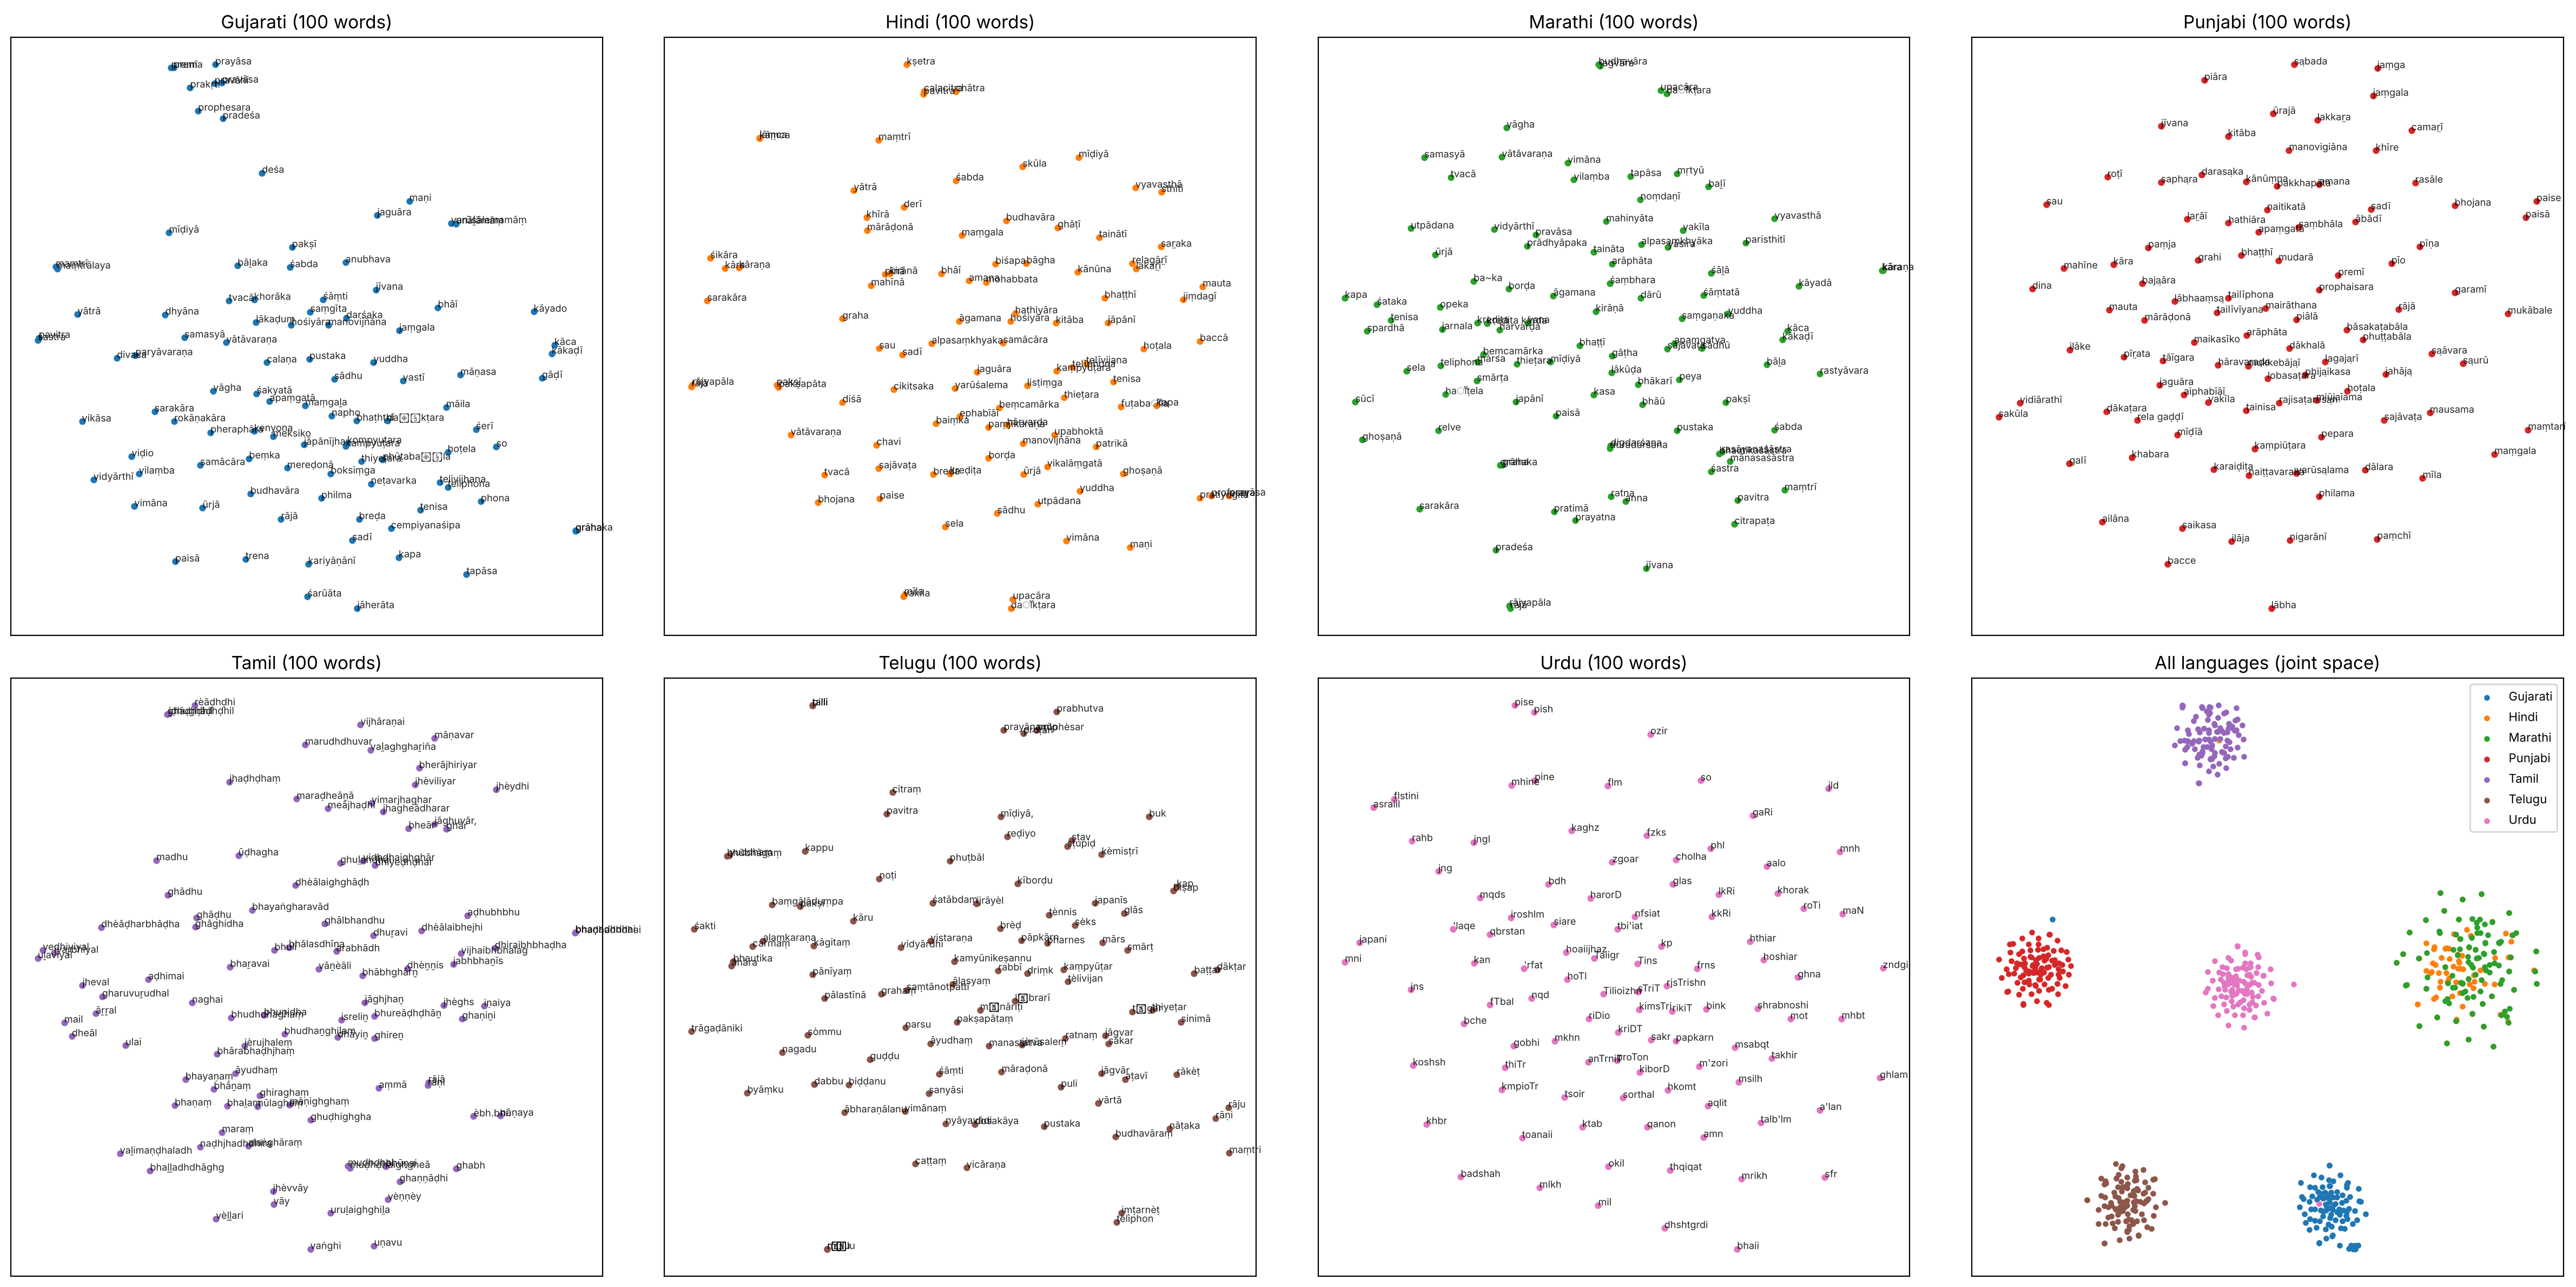

In [11]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate
SCHEME = {'Hindi':sanscript.DEVANAGARI, 'Marathi':sanscript.DEVANAGARI, 'Gujarati':sanscript.GUJARATI,
          'Punjabi':sanscript.GURMUKHI, 'Tamil':sanscript.TAMIL, 'Telugu':sanscript.TELUGU}
URDU = dict(zip('ابپتٹثجچحخدڈذرڑزژسشصضطظعغفقکگلمنںوہھءیےآأؤئۓة',
  ['a','b','p','t','T','s','j','ch','h','kh','d','D','z','r','R','z','zh','s','sh','s','z','t','z',"'",'gh','f','q','k','g','l','m','n','N','o','h','h',"'",'i','e','aa','a','o','i','e','h']))
def roman(L, w):
    if L == 'Urdu': return ''.join(URDU.get(c, '') for c in w)
    try: return transliterate(w, SCHEME[L], sanscript.IAST)
    except Exception: return w

lang_freq = {}
for L in BENCH_LANGS:
    keys = {L} | ({'Devanagari(unk)'} if L in ('Hindi', 'Marathi') else set())
    lang_freq[L] = Counter(w for t in corpus_df[corpus_df.lang.isin(keys)].text for w in tokenize(t))

def sample_words(L, n=100):
    ws = list(dict.fromkeys(list(BENCH[L].w1) + list(BENCH[L].w2)))[:n]
    for w, _ in lang_freq[L].most_common():
        if len(ws) >= n: break
        if len(w) > 1 and w not in ws and not w.isdigit(): ws.append(w)
    return ws[:n]

fig, axes = plt.subplots(2, 4, figsize=(24, 12)); axes = axes.ravel()
all_pts, all_lab = [], []
for k, L in enumerate(BENCH_LANGS):
    ws = sample_words(L); X = np.stack([embed(final_model, w) for w in ws])
    Y = TSNE(n_components=2, perplexity=15, random_state=SEED, init='pca').fit_transform(X)
    ax = axes[k]; ax.scatter(Y[:, 0], Y[:, 1], s=12, c=f'C{k}')
    for (x, y), w in zip(Y, ws): ax.annotate(roman(L, w)[:14], (x, y), fontsize=6.5, alpha=.85)
    ax.set_title(f'{L} ({len(ws)} words)'); ax.set_xticks([]); ax.set_yticks([])
    all_pts.append(X); all_lab += [L] * len(ws)
Yall = TSNE(n_components=2, perplexity=30, random_state=SEED, init='pca').fit_transform(np.vstack(all_pts))
ax = axes[7]
for k, L in enumerate(BENCH_LANGS):
    m = np.array(all_lab) == L; ax.scatter(Yall[m, 0], Yall[m, 1], s=8, c=f'C{k}', label=L)
ax.legend(fontsize=8); ax.set_title('All languages (joint space)'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'tsne.png'), dpi=150); plt.show()

## 12. Analysis — correctly vs incorrectly predicted pairs
Model and human scores are converted to percentile ranks within each language; small |Δrank| = good agreement, large = error.

In [12]:
an_rows = []
for L, df in BENCH.items():
    d = df[df.human.notna()].copy()
    d['model'] = [cosine(embed(final_model, a), embed(final_model, b)) for a, b in zip(d.w1, d.w2)]
    d['h_rank'] = d.human.rank(pct=True); d['m_rank'] = d.model.rank(pct=True)
    d['abs_err'] = (d.h_rank - d.m_rank).abs(); d['lang'] = L
    d['oov'] = [(not is_in_vocab(final_model, a)) or (not is_in_vocab(final_model, b)) for a, b in zip(d.w1, d.w2)]
    an_rows.append(d)
an = pd.concat(an_rows)
an['w1_rom'] = [roman(L, w) for L, w in zip(an.lang, an.w1)]; an['w2_rom'] = [roman(L, w) for L, w in zip(an.lang, an.w2)]
an.to_csv(os.path.join(OUT_DIR, 'pair_analysis.csv'), index=False)
cols = ['lang', 'w1', 'w2', 'w1_rom', 'w2_rom', 'human', 'model', 'abs_err', 'oov']
good = an[an.w1 != an.w2].sort_values('abs_err').groupby('lang').head(1)
bad = an.sort_values('abs_err', ascending=False).groupby('lang').head(1)
print('Correctly ranked (one per language):'); display(good[cols].round(3))
print('Incorrectly ranked (one per language):'); display(bad[cols].round(3))
print('Mean |rank error| in-vocab pairs vs pairs with OOV:'); print(an.groupby('oov').abs_err.mean().round(3))

Correctly ranked (one per language):


,lang,w1,w2,w1_rom,w2_rom,human,model,abs_err,oov
122,Gujarati,જાહેરાત,ચેતવણી,jāherāta,cetavaṇī,8.000,0.668,0.000,False
160,Hindi,लाभांश,भुगतान,lābhāṃśa,bhugatāna,7.800,0.594,0.000,False
10,Tamil,மருத்துவர்,செவிலியர்,marudhdhuvar,jhèviliyar,7.500,0.675,0.000,True
54,Punjabi,ਮਨੋਵਿਗਿਆਨ,ਸਿਹਤ,manovigiāna,sihata,4.500,0.540,0.003,False
81,Telugu,జాగ్వార్,కార్,jāgvār,kār,8.000,0.773,0.005,True
43,Marathi,रत्न,रत्नजडित,ratna,ratnajaḍita,9.375,0.767,0.005,True
80,Urdu,اعلان,کوشش,a'lan,koshsh,0.500,0.414,0.005,False


Incorrectly ranked (one per language):


,lang,w1,w2,w1_rom,w2_rom,human,model,abs_err,oov
47,Hindi,पैसे,मुद्रा,paise,mudrā,8.60,0.314,0.917,False
29,Marathi,अराफात,जॅक्सन,arāphāta,jaॅksana,0.00,0.650,0.913,True
28,Tamil,அரபாத்,ஜாக்சன்,arabhādh,jāghjhaṉ,0.00,0.810,0.875,True
78,Punjabi,ਮੰਤਰੀ,ਪਾਰਟੀ,maṃtarī,pāraṭī,8.75,0.466,0.871,False
107,Telugu,మైనారిటీ,శాంతి,mèౖnāriṭī,śāṃti,1.00,0.782,0.842,True
87,Urdu,زندگی,موت,zndgi,mot,9.00,0.382,0.835,False
81,Gujarati,મંગળ,પાણી,maṃgaḻa,pāṇī,9.00,0.456,0.813,False


Mean |rank error| in-vocab pairs vs pairs with OOV:
oov
False    0.272
True     0.309
Name: abs_err, dtype: float64


## 13. Inference API for the private test set (self-contained)
This cell does **not** need the corpus or any earlier cell. It needs only `model/compact/`. It loads the trained model and embeds **any** word, including OOV words, via character n-grams. `embed_pairs_file` turns a word-pair file (tab- or comma-separated, scores optional) into the required `(N, 2, 300)` float32 array, preserving the original order.

In [13]:
import os, json, re, unicodedata, numpy as np, pandas as pd, regex
from gensim.models.fasttext import FastTextKeyedVectors

_TOK = regex.compile(r'[\p{L}\p{M}\p{N}]+')
def _tokenize(s):
    s = unicodedata.normalize('NFC', s)
    s = ''.join(ch for ch in s if unicodedata.category(ch) != 'Cf').lower()
    return _TOK.findall(s)

def load_model(d='model/compact'):
    m = json.load(open(f'{d}/meta.json'))
    wv = FastTextKeyedVectors(m['vector_size'], m['min_n'], m['max_n'], m['bucket'])
    keys = open(f'{d}/vocab.txt', encoding='utf-8').read().split('\n')
    wv.index_to_key = keys; wv.key_to_index = {k: i for i, k in enumerate(keys)}
    deq = lambda n: np.load(f'{d}/{n}_int8.npy').astype(np.float32) * np.load(f'{d}/{n}_scale.npy')
    wv.vectors_vocab, wv.vectors_ngrams = deq('vectors_vocab'), deq('vectors_ngrams')
    wv.vectors = np.zeros_like(wv.vectors_vocab); wv.recalc_char_ngram_buckets(); wv.adjust_vectors()
    return wv

def get_embedding(word, wv):
    """300-d unit-norm vector for any string: in-vocabulary, OOV (char n-grams) or multi-word (token mean)."""
    toks = _tokenize(word) or [word.strip() or word]
    v = np.mean([wv[t] / (np.linalg.norm(wv[t]) or 1.0) for t in toks], axis=0)
    return (v / (np.linalg.norm(v) or 1.0)).astype(np.float32) if len(toks) == 1 else v.astype(np.float32)

def read_pairs(path):
    rows = []
    for line in open(path, encoding='utf-8-sig'):
        line = line.strip('\r\n')
        if not line.strip(): continue
        p = [x.strip() for x in (line.split('\t') if '\t' in line else line.split(','))]
        p = [x for x in p if x]
        if len(p) >= 2: rows.append((p[0], p[1]))
    return rows

def embed_pairs_file(path, wv, out_npy=None):
    pairs = read_pairs(path)
    arr = np.stack([[get_embedding(a, wv), get_embedding(b, wv)] for a, b in pairs]).astype(np.float32)
    assert arr.shape == (len(pairs), 2, 300)
    if out_npy: np.save(out_npy, arr)
    return arr

wv = load_model(os.path.join(MODEL_DIR, 'compact') if 'MODEL_DIR' in globals() else 'model/compact')
for w in ['किताब', 'किताबें', 'पुस्तकालयों', 'ਕਿਤਾਬਾਂ', 'புத்தகங்கள்', 'کمپیوٹر', 'کی بورڈ', 'xyzunseenword']:
    v = get_embedding(w, wv)
    print(f'{w:14s} in_vocab={all(t in wv.key_to_index for t in _tokenize(w))!s:5s} dim={v.shape[0]} norm={np.linalg.norm(v):.3f}')
c = lambda a, b: float(get_embedding(a, wv) @ get_embedding(b, wv) / np.linalg.norm(get_embedding(a, wv)) / np.linalg.norm(get_embedding(b, wv)))
print('cos(किताब, किताबें) =', round(c('किताब', 'किताबें'), 3), '| cos(किताब, पुस्तकालयों) =', round(c('किताब', 'पुस्तकालयों'), 3))

# Example: regenerate the public-benchmark arrays and check they match the exported ones
for L in ['Hindi', 'Urdu']:
    path = os.path.join(BENCH_DIR, f'{L}-WS.txt') if 'BENCH_DIR' in globals() else f'data/ws/{L}-WS.txt'
    if not os.path.exists(path): continue
    arr = embed_pairs_file(path, wv)
    ref = np.load(os.path.join(OUT_DIR, 'embeddings', f'{L}_embeddings.npy')) if 'OUT_DIR' in globals() else arr
    print(L, arr.shape, 'matches export:', np.allclose(arr, ref, atol=1e-5))
# Private test usage:  embed_pairs_file('Hindi-test.txt', wv, 'Hindi_test_embeddings.npy')

किताब          in_vocab=True  dim=300 norm=1.000
किताबें        in_vocab=True  dim=300 norm=1.000
पुस्तकालयों    in_vocab=False dim=300 norm=1.000
ਕਿਤਾਬਾਂ        in_vocab=True  dim=300 norm=1.000
புத்தகங்கள்    in_vocab=True  dim=300 norm=1.000
کمپیوٹر        in_vocab=True  dim=300 norm=1.000
کی بورڈ        in_vocab=True  dim=300 norm=0.863
xyzunseenword  in_vocab=False dim=300 norm=1.000
cos(किताब, किताबें) = 0.89 | cos(किताब, पुस्तकालयों) = 0.576
Hindi (235, 2, 300) matches export: True
Urdu (100, 2, 300) matches export: True
